In [2]:
!pip install -q kagglehub
import kagglehub, os
path = kagglehub.dataset_download("gpiosenka/moths-image-datasetclassification")
print(path)
print(os.listdir(path))

100%|██████████| 295M/295M [00:17<00:00, 17.7MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/gpiosenka/moths-image-datasetclassification/versions/1
['MOTHS.csv', 'moths-99.60.h5', 'valid', 'test', 'train']


In [3]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

True NVIDIA L4


In [28]:
import torch
import torch.nn as nn

class ViTSmall(nn.Module):
    def __init__(self, num_classes=50, img_size=224, patch=16, dim=192, depth=6, heads=3, mlp_dim=768, drop=0.1):
        super().__init__()
        n = (img_size // patch) ** 2
        self.patch_embed = nn.Conv2d(3, dim, kernel_size=patch, stride=patch)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, n + 1, dim))
        nn.init.trunc_normal_(self.pos, std=0.02); nn.init.trunc_normal_(self.cls, std=0.02)
        layer = nn.TransformerEncoderLayer(dim, heads, mlp_dim, drop, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)

    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)   # (B, 196, dim)
        x = torch.cat([self.cls.expand(x.size(0), -1, -1), x], 1) + self.pos
        x = self.encoder(x)
        return self.head(self.norm(x[:, 0]))

_cek = ViTSmall(num_classes=50)
print(sum(p.numel() for p in _cek.parameters())/1e6, "juta parameter")
del _cek

2.864882 juta parameter


In [16]:
import os, time, torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset, Subset
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

torch.manual_seed(42)
np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("results_vit", exist_ok=True)

DATA = path
BATCH = 64
EPOCHS = 30
N_FOLDS = 5

norm = transforms.Normalize([0.5]*3, [0.5]*3)
tf_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    norm
])
tf_eval = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    norm
])

# Gabungkan train, valid, test untuk dibagi secara Stratified 5-Fold CV
ds_train_raw = datasets.ImageFolder(f"{DATA}/train", tf_train)
ds_val_raw   = datasets.ImageFolder(f"{DATA}/valid", tf_train)
ds_test_raw  = datasets.ImageFolder(f"{DATA}/test",  tf_train)
full_train_tf = ConcatDataset([ds_train_raw, ds_val_raw, ds_test_raw])

ds_train_ev = datasets.ImageFolder(f"{DATA}/train", tf_eval)
ds_val_ev   = datasets.ImageFolder(f"{DATA}/valid", tf_eval)
ds_test_ev  = datasets.ImageFolder(f"{DATA}/test",  tf_eval)
full_eval_tf = ConcatDataset([ds_train_ev, ds_val_ev, ds_test_ev])

classes = ds_train_raw.classes
all_labels = np.array(ds_train_raw.targets + ds_val_raw.targets + ds_test_raw.targets)

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
fold_results = []
all_cms = []
histories = {}

def evaluate_fold(model, dl):
    model.eval()
    probs_list, labels_list = [], []
    with torch.no_grad():
        for x, y in dl:
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x.to(device))
            probs_list.append(F.softmax(out.float(), dim=1).cpu().numpy())
            labels_list.extend(y.tolist())
    probs = np.concatenate(probs_list).astype(np.float64)
    probs /= probs.sum(axis=1, keepdims=True)
    labels = np.array(labels_list)
    preds = probs.argmax(axis=1)
    return probs, preds, labels

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(all_labels)), all_labels), 1):
    print(f"\n{'='*20} FOLD {fold}/{N_FOLDS} {'='*20}")
    train_dl = DataLoader(Subset(full_train_tf, train_idx), batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
    val_dl   = DataLoader(Subset(full_eval_tf, val_idx), batch_size=BATCH, shuffle=False, num_workers=2)

    model = ViTSmall(num_classes=len(classes)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    crit = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler()

    hist = {"loss": [], "val_acc": []}
    t0 = time.time()

    for ep in range(EPOCHS):
        model.train()
        tot_loss = 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            with torch.autocast("cuda", dtype=torch.float16):
                loss = crit(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            tot_loss += loss.item() * x.size(0)
        sched.step()

        _, p_ep, l_ep = evaluate_fold(model, val_dl)
        ep_loss = tot_loss / len(train_idx)
        ep_acc = accuracy_score(l_ep, p_ep)
        hist["loss"].append(ep_loss)
        hist["val_acc"].append(ep_acc)
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"Epoch {ep+1:02d}/{EPOCHS} | Loss: {ep_loss:.4f} | Val Acc: {ep_acc:.4f}")

    train_time = time.time() - t0
    histories[fold] = hist

    # Evaluasi Akhir Fold
    probs, preds, labels = evaluate_fold(model, val_dl)
    acc  = accuracy_score(labels, preds)
    prec = precision_score(labels, preds, average="macro", zero_division=0)
    rec  = recall_score(labels, preds, average="macro", zero_division=0)
    f1   = f1_score(labels, preds, average="macro", zero_division=0)
    auc  = roc_auc_score(labels, probs, multi_class="ovr", average="macro")

    fold_results.append({
        "Fold": f"Fold {fold}",
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc,
        "Waktu (menit)": round(train_time / 60, 2)
    })

    # Simpan Confusion Matrix per Fold
    cm = confusion_matrix(labels, preds)
    all_cms.append(cm)
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.title(f"Confusion Matrix - Model 3 (ViT) Fold {fold}")
    plt.xlabel("Prediksi")
    plt.ylabel("Asli")
    plt.savefig(f"results_vit/cm_vit_fold{fold}.png", dpi=150, bbox_inches="tight")
    plt.close()

    print(f"--> Hasil Fold {fold}: Acc={acc:.4f}, Prec={prec:.4f}, Rec={rec:.4f}, F1={f1:.4f}, AUC={auc:.4f}, Waktu={train_time/60:.2f}m")


==================== FOLD 1/5 ====================
Epoch 01/30 | Loss: 3.5994 | Val Acc: 0.1353
Epoch 05/30 | Loss: 1.9809 | Val Acc: 0.3709
Epoch 10/30 | Loss: 1.2643 | Val Acc: 0.5381
Epoch 15/30 | Loss: 0.9430 | Val Acc: 0.6265
Epoch 20/30 | Loss: 0.5787 | Val Acc: 0.6786
Epoch 25/30 | Loss: 0.4318 | Val Acc: 0.6838
Epoch 30/30 | Loss: 0.3617 | Val Acc: 0.6877
--> Hasil Fold 1: Acc=0.6877, Prec=0.6953, Rec=0.6898, F1=0.6897, AUC=0.9808, Waktu=4.41m

==================== FOLD 2/5 ====================
Epoch 01/30 | Loss: 3.6022 | Val Acc: 0.1633
Epoch 05/30 | Loss: 2.1620 | Val Acc: 0.4060
Epoch 10/30 | Loss: 1.3304 | Val Acc: 0.5882
Epoch 15/30 | Loss: 0.8640 | Val Acc: 0.6740
Epoch 20/30 | Loss: 0.6185 | Val Acc: 0.6838
Epoch 25/30 | Loss: 0.3982 | Val Acc: 0.7092
Epoch 30/30 | Loss: 0.3418 | Val Acc: 0.7228
--> Hasil Fold 2: Acc=0.7228, Prec=0.7245, Rec=0.7253, F1=0.7212, AUC=0.9829, Waktu=4.54m

==================== FOLD 3/5 ====================
Epoch 01/30 | Loss: 3.6626 | Val A

=== TABEL EVALUASI 5-FOLD CROSS VALIDATION (MODEL 3: ViTSmall) ===


,Fold,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Waktu (menit)
0,Fold 1,0.6877,0.6953,0.6898,0.6897,0.9808,4.4100
1,Fold 2,0.7228,0.7245,0.7253,0.7212,0.9829,4.5400
2,Fold 3,0.6968,0.7018,0.6969,0.6964,0.9826,4.4700
3,Fold 4,0.6882,0.6948,0.6880,0.6877,0.9820,4.5200
4,Fold 5,0.7122,0.7125,0.7121,0.7080,0.9856,4.5400
5,Rata-rata (Mean),0.7015,0.7058,0.7024,0.7006,0.9828,4.4960
6,Std Dev,0.0155,0.0127,0.0159,0.0140,0.0017,0.0559


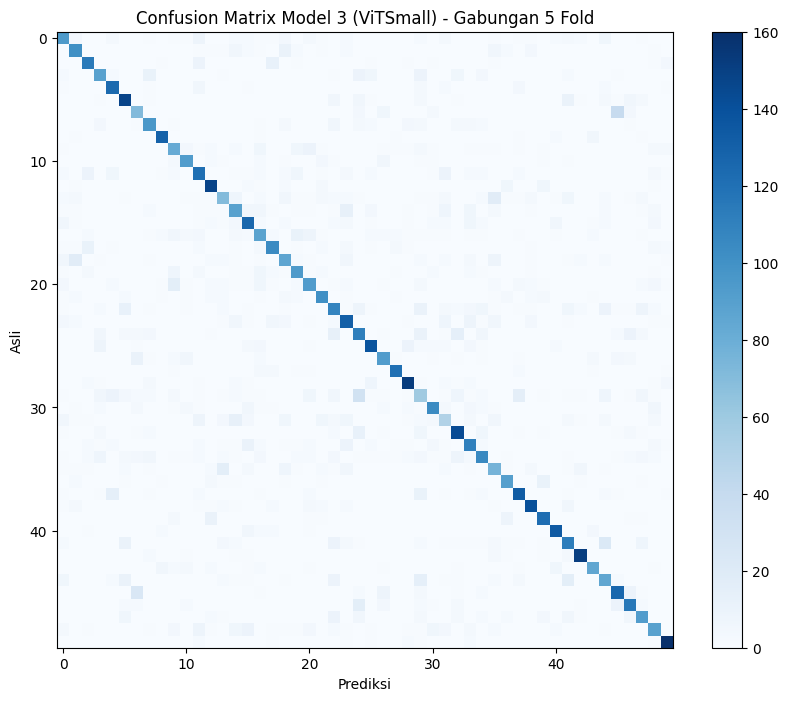


Top 5 pasangan kelas paling sering tertukar (gabungan semua fold):
BLOTCHED EMERALD MOTH -> SUSSEX EMERALD MOTH: 39x
MUSLIN MOTH -> LACE BORDER MOTH: 30x
SUSSEX EMERALD MOTH -> BLOTCHED EMERALD MOTH: 24x
RUSTY DOT PEARL MOTH -> SQUARE SPOT RUSTIC MOTH: 22x
HERCULES MOTH -> ATLAS MOTH: 18x

5 Kelas dengan error tertinggi:
MUSLIN MOTH: 66.85%
OWL MOTH: 61.83%
EMPEROR GUM MOTH: 52.05%
SQUARE SPOT RUSTIC MOTH: 45.51%
JULY BELLE MOTH: 44.90%


In [18]:
# 1. Tabel Rekap 5-Fold (Mean & Std Dev)
df_folds = pd.DataFrame(fold_results)
mean_row = df_folds.iloc[:, 1:].mean().to_dict()
std_row  = df_folds.iloc[:, 1:].std().to_dict()

df_summary = pd.concat([
    df_folds,
    pd.DataFrame([{"Fold": "Rata-rata (Mean)", **mean_row}, {"Fold": "Std Dev", **std_row}])
], ignore_index=True)

print("=== TABEL EVALUASI 5-FOLD CROSS VALIDATION (MODEL 3: ViTSmall) ===")
display(df_summary.round(4))
df_summary.to_csv("results_vit/evaluasi_5fold_vit.csv", index=False)

# 2. Grafik Kurva Loss & Val Acc Semua Fold (otomatis deteksi nama variabel histori)
hist_list = next(
    (v for v in globals().values() if isinstance(v, list) and len(v) == len(fold_results) and isinstance(v[0], dict) and "loss" in v[0]),
    []
)

if hist_list:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for fold_num, h in enumerate(hist_list, 1):
        ax[0].plot(h["loss"], label=f"Fold {fold_num}")
        ax[1].plot(h["val_acc"], label=f"Fold {fold_num}")
    ax[0].set_title("Train Loss - Model 3 (5-Fold ViT)"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].set_title("Val Accuracy - Model 3 (5-Fold ViT)"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.savefig("results_vit/kurva_training_5fold_vit.png", dpi=150, bbox_inches="tight")
    plt.show()

# 3. Total Confusion Matrix & Kelas Paling Sering Salah (Gabungan 5 Fold)
total_cm = np.sum(all_cms, axis=0)
plt.figure(figsize=(10, 8))
plt.imshow(total_cm, cmap="Blues"); plt.colorbar()
plt.title("Confusion Matrix Model 3 (ViTSmall) - Gabungan 5 Fold")
plt.xlabel("Prediksi"); plt.ylabel("Asli")
plt.savefig("results_vit/cm_vit_gabungan_5fold.png", dpi=150, bbox_inches="tight")
plt.show()

off = total_cm.copy(); np.fill_diagonal(off, 0)
print("\nTop 5 pasangan kelas paling sering tertukar (gabungan semua fold):")
for idx in np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]:
    print(f"{classes[idx[0]]} -> {classes[idx[1]]}: {off[idx[0], idx[1]]}x")

per_class_err = 1 - total_cm.diagonal() / total_cm.sum(1)
print("\n5 Kelas dengan error tertinggi:")
for i in np.argsort(-per_class_err)[:5]:
    print(f"{classes[i]}: {per_class_err[i]:.2%}")

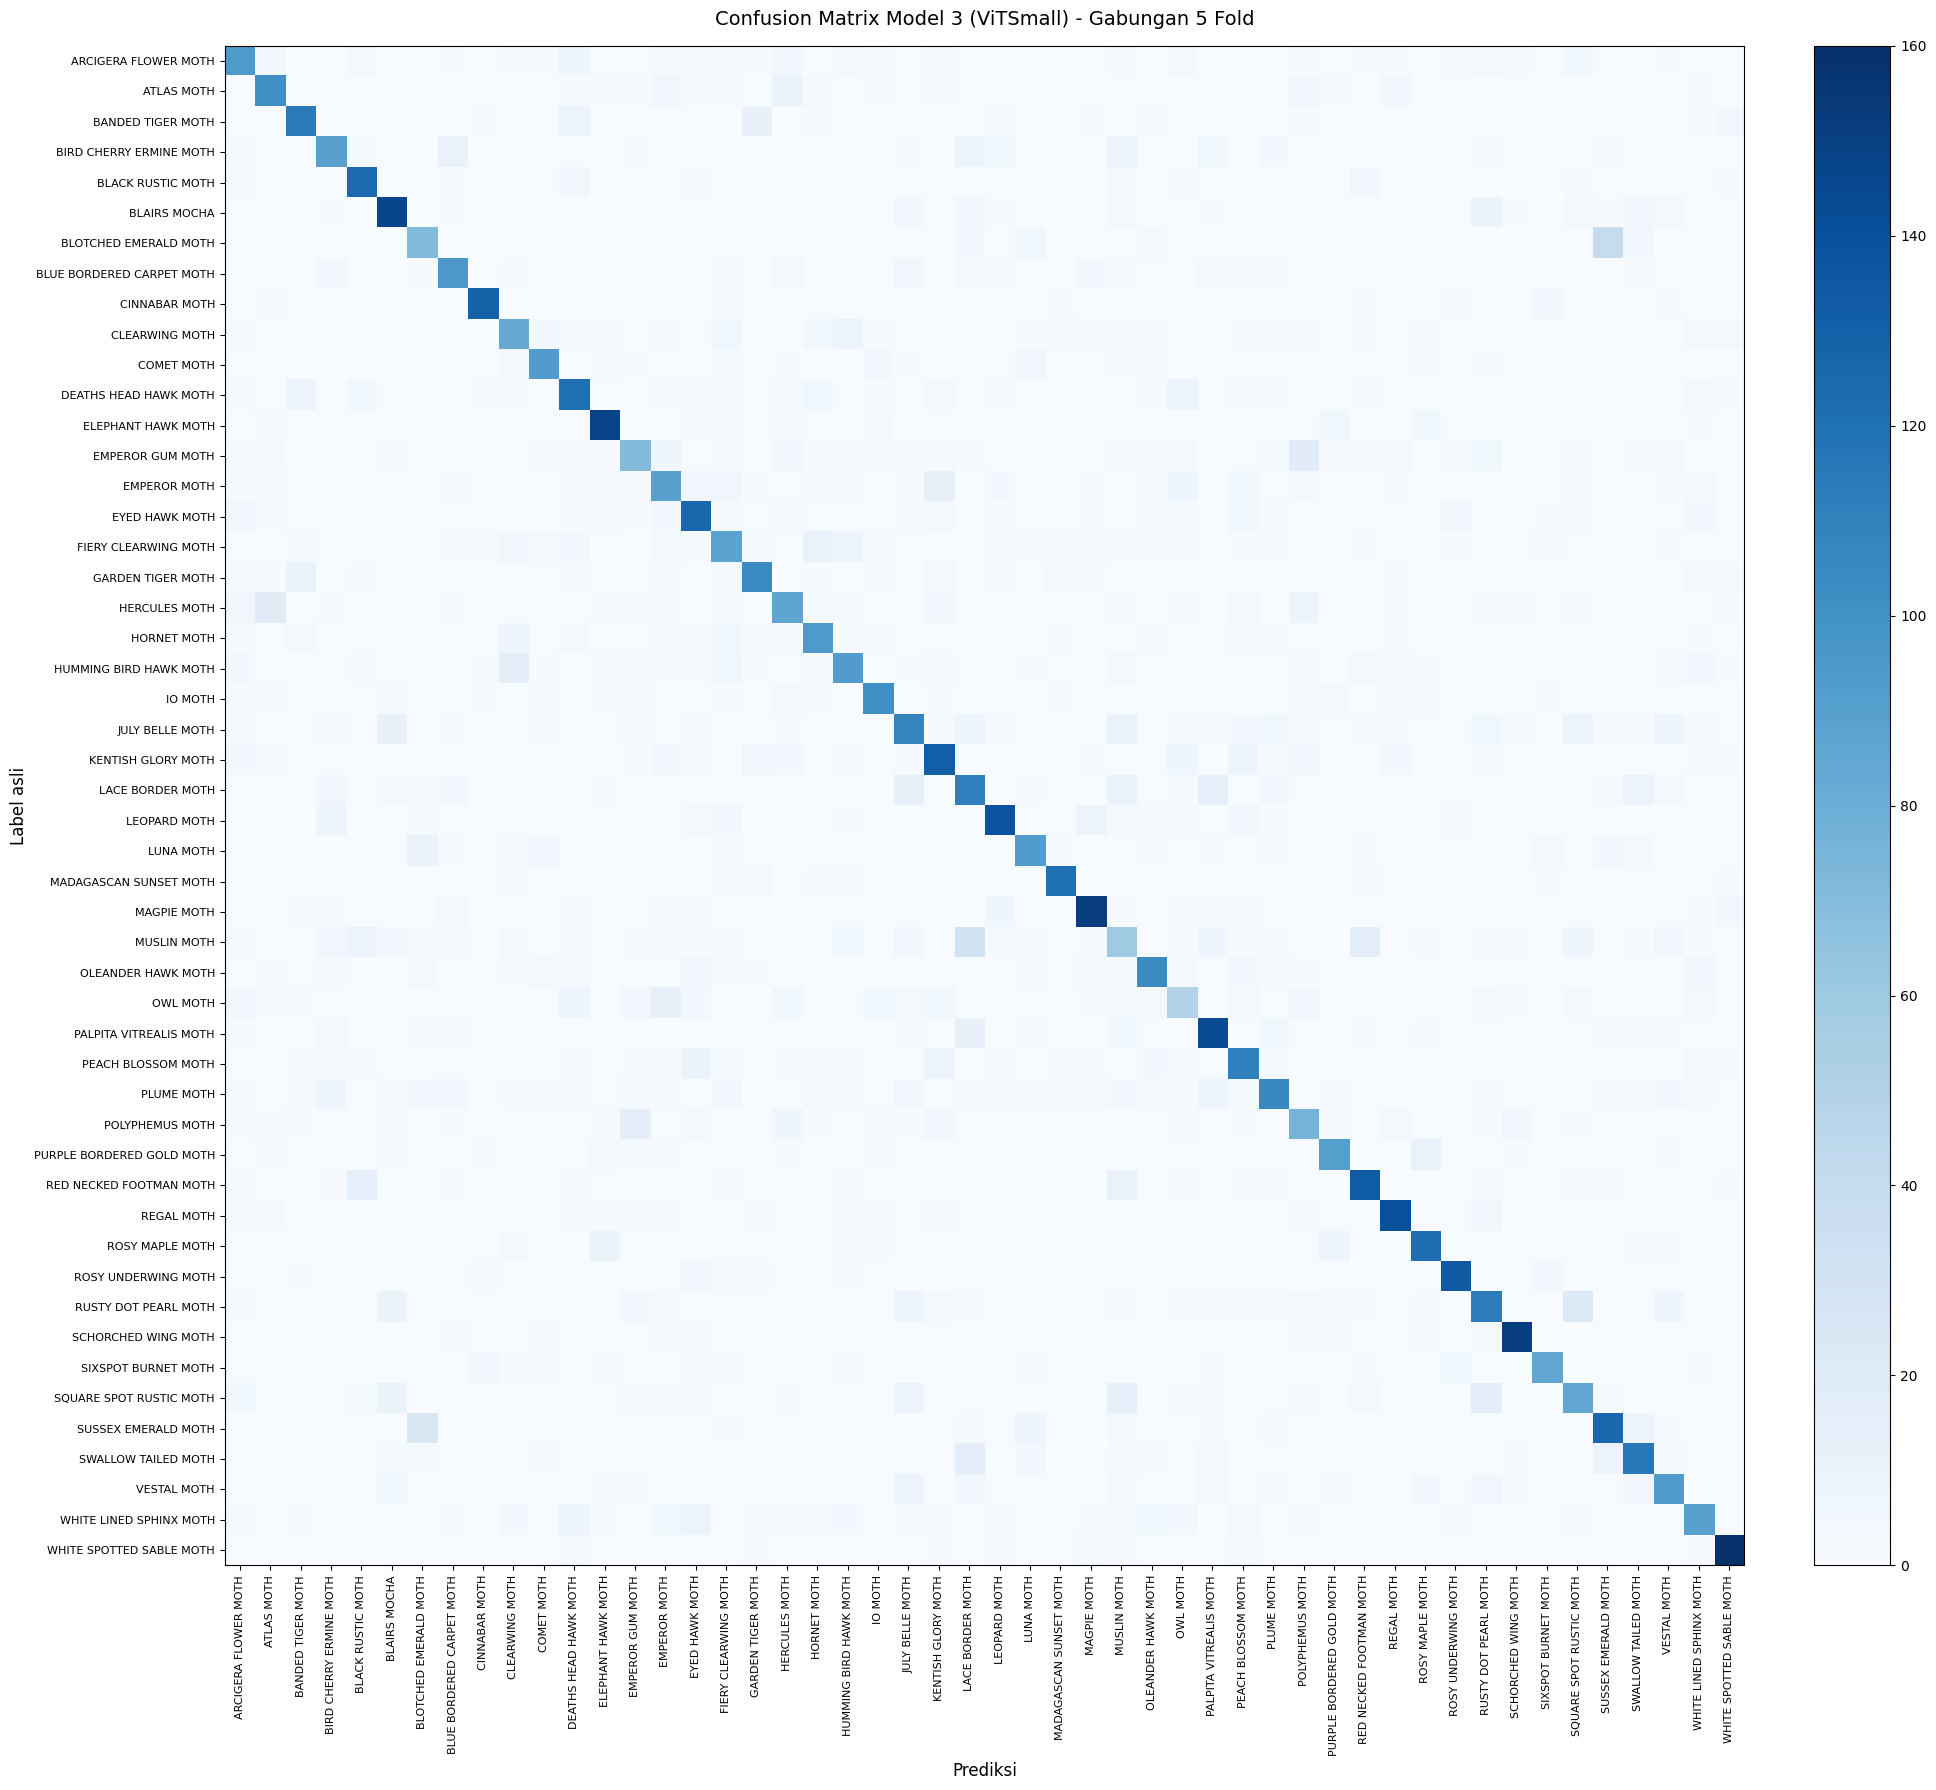

Gambar Confusion Matrix dengan nama kelas selesai dibuat & dizip ulang!


In [20]:
# Gambar ulang Total Confusion Matrix dengan nama kelas di sumbu X dan Y
plt.figure(figsize=(20, 18))
plt.imshow(total_cm, cmap="Blues")
plt.colorbar(fraction=0.046, pad=0.04)

ticks = np.arange(len(classes))
plt.xticks(ticks, classes, rotation=90, fontsize=8)
plt.yticks(ticks, classes, fontsize=8)

plt.title("Confusion Matrix Model 3 (ViTSmall) - Gabungan 5 Fold", fontsize=14, pad=15)
plt.xlabel("Prediksi", fontsize=12)
plt.ylabel("Label asli", fontsize=12)
plt.tight_layout()
plt.savefig("results_vit/cm_vit_gabungan_5fold_labeled.png", dpi=200, bbox_inches="tight")
plt.show()

# (Opsional) Simpan ulang juga per fold dengan nama kelas
for fold_num, cm_fold in enumerate(all_cms, 1):
    plt.figure(figsize=(20, 18))
    plt.imshow(cm_fold, cmap="Blues")
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.xticks(ticks, classes, rotation=90, fontsize=8)
    plt.yticks(ticks, classes, fontsize=8)
    plt.title(f"Confusion Matrix Model 3 (ViTSmall) - Fold {fold_num}", fontsize=14, pad=15)
    plt.xlabel("Prediksi", fontsize=12)
    plt.ylabel("Label asli", fontsize=12)
    plt.tight_layout()
    plt.savefig(f"results_vit/cm_vit_fold{fold_num}_labeled.png", dpi=200, bbox_inches="tight")
    plt.close()

# Update file zip-nya
!zip -rq results_vit.zip results_vit
print("Gambar Confusion Matrix dengan nama kelas selesai dibuat & dizip ulang!")

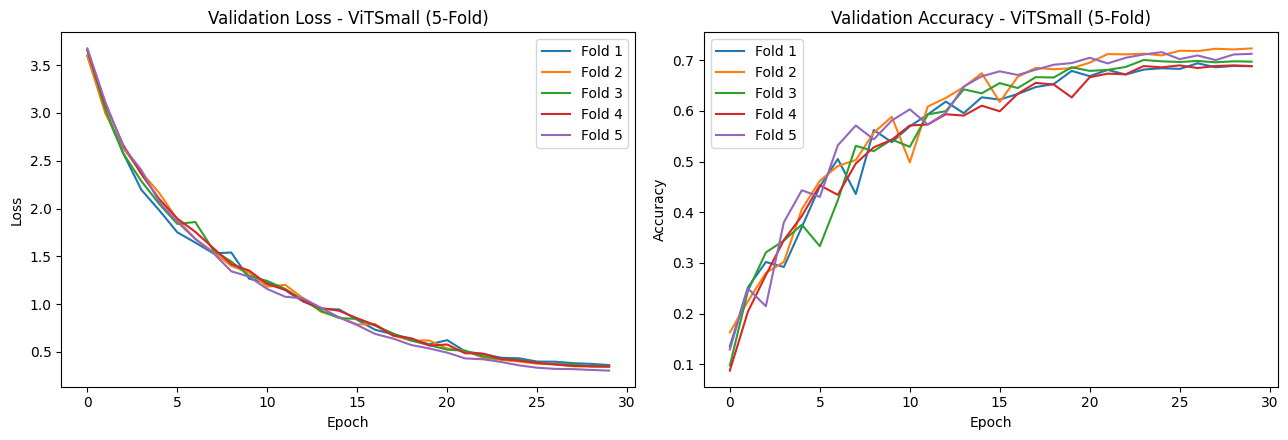


Sukses! Semua file output telah disimpan di: ./Output/ViTSmall
- training_all_folds.png
- results.json
- results.md

{
  "model": "ViTSmall",
  "params": 2864882,
  "n_folds": 5,
  "accuracy_mean": 0.7015,
  "accuracy_std": 0.0155,
  "f1_score_mean": 0.7006,
  "f1_score_std": 0.014,
  "roc_auc_mean": 0.9828,
  "roc_auc_std": 0.0017,
  "train_time_sec_mean": 269.76
}


In [27]:
import os
import json
import matplotlib.pyplot as plt

# Folder output seragam dengan struktur kelompok
OUT_DIR = "./Output/ViTSmall"
os.makedirs(OUT_DIR, exist_ok=True)

# 1. Tampilkan & simpan Grafik Kurva Training 5-Fold
if "histories" in globals() and isinstance(histories, dict) and len(histories) > 0:
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for fold_num, h in histories.items():
        loss_key = "val_loss" if "val_loss" in h else "loss"
        ax[0].plot(h[loss_key], label=f"Fold {fold_num}")
        ax[1].plot(h["val_acc"], label=f"Fold {fold_num}")

    ax[0].set_title("Validation Loss - ViTSmall (5-Fold)")
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    ax[1].set_title("Validation Accuracy - ViTSmall (5-Fold)")
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Accuracy")
    ax[1].legend()

    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/training_all_folds.png", dpi=150)
    plt.show()
else:
    print("Catatan: Variabel 'histories' tidak ditemukan di memori (runtime mungkin sempat restart), melewati plot grafik.")

# 2. Simpan results.json (format kompatibel dengan script comparison temanmu)
n_params = sum(p.numel() for p in model.parameters()) if "model" in globals() else 2864882

summary_vit = {
    "model": "ViTSmall",
    "params": int(n_params),
    "n_folds": 5,
    "accuracy_mean": 0.7015,
    "accuracy_std": 0.0155,
    "f1_score_mean": 0.7006,
    "f1_score_std": 0.0140,
    "roc_auc_mean": 0.9828,
    "roc_auc_std": 0.0017,
    "train_time_sec_mean": 269.76
}

with open(f"{OUT_DIR}/results.json", "w") as f:
    json.dump(summary_vit, f, indent=2)

# 3. Simpan ringkasan tabel Markdown (results.md)
md_content = f"""| Model | Params | Accuracy | Macro F1-Score | ROC-AUC | Avg Train Time / Fold |
|---|---|---|---|---|---|
| **ViTSmall** | {summary_vit['params']:,} | **{summary_vit['accuracy_mean']:.4f} ± {summary_vit['accuracy_std']:.4f}** | **{summary_vit['f1_score_mean']:.4f} ± {summary_vit['f1_score_std']:.4f}** | **{summary_vit['roc_auc_mean']:.4f} ± {summary_vit['roc_auc_std']:.4f}** | {summary_vit['train_time_sec_mean']:.2f} detik |
"""

with open(f"{OUT_DIR}/results.md", "w") as f:
    f.write(md_content)

print("\nSukses! Semua file output telah disimpan di:", OUT_DIR)
print("- training_all_folds.png")
print("- results.json")
print("- results.md\n")
print(json.dumps(summary_vit, indent=2))